# Feature extraction – visual data exploration

This notebook explores the frame-level CSV produced by `extract_features.py`. It is designed to help understand tracking quality, ball movement, player proximity, temporal signals and Smart Tagging **before tuning the possession prediction rules**.

**Input:** one row per video frame from `*_features.csv`.

## 1. Setup and load the feature CSV

Dependencies: `pandas`, `numpy`, `matplotlib`. Install if needed:

```bash
uv add pandas numpy matplotlib
```

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [20]:
CSV_PATH = Path("../data/derived/BAR-ATH_features_corrected.csv")

df = pd.read_csv(CSV_PATH)
df = df.sort_values("frame").reset_index(drop=True)

print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
display(df.head())

Rows: 199,319 | Columns: 35


/var/folders/qt/d9mrqr1s6z536_h0j4_x7wpc0000gp/T/ipykernel_8264/2452730014.py:3: DtypeWarning: Columns (31: tag_set_piece_type) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(CSV_PATH)


,frame,half,graded,ball_x,ball_y,ball_missing,ball_out,ball_speed,ball_speed_smooth,ball_accel,...,nearest_home_share_25f,nearest_away_share_25f,nearest_home_share_50f,nearest_away_share_50f,nearest_team_run_frames,tag_dead,tag_set_piece_type,tag_goal,tag_team_poss,tag_team_def
0,0,0,False,NaN,NaN,True,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,False,NaN,False,-1,-1
1,1,0,False,NaN,NaN,True,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,False,NaN,False,-1,-1
2,2,0,False,NaN,NaN,True,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,False,NaN,False,-1,-1
3,3,0,False,NaN,NaN,True,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,False,NaN,False,-1,-1
4,4,0,False,NaN,NaN,True,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,False,NaN,False,-1,-1


## 2. Understand the table and data quality

Column types, missingness and value ranges. Missing values are meaningful here: for example, missing ball coordinates mean the ball was not tracked in that frame.

In [21]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (100 * df.isna().mean()).round(2),
    "n_unique": df.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False))

display(df.describe(include="all").T)

,dtype,missing_n,missing_pct,n_unique
tag_set_piece_type,str,155332,77.93,6
d_home_change_10f,float64,88298,44.30,110814
d_away_change_10f,float64,87589,43.94,111458
margin,float64,86900,43.60,112316
d_home,float64,86730,43.51,112412
d_away,float64,86001,43.15,113140
ball_speed,float64,86016,43.15,103670
ball_y,float64,85831,43.06,68590
ball_x,float64,85831,43.06,63698
ball_accel,float64,85465,42.88,101261


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
frame,199319.0,NaN,NaN,NaN,99659.0,57538.58349,0.0,49829.5,99659.0,149488.5,199318.0
half,199319.0,NaN,NaN,NaN,1.195305,0.750444,0.0,1.0,1.0,2.0,2.0
graded,199319,2,True,158857,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ball_x,113488.0,NaN,NaN,NaN,52.928782,25.200708,-6.862401,33.564113,55.772671,71.10172,117.28841
ball_y,113488.0,NaN,NaN,NaN,38.798074,19.338274,-7.28484,24.27107,39.78238,54.71008,101.22072
ball_missing,199319,2,False,113488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ball_out,199319,2,False,195011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ball_speed,113303.0,NaN,NaN,NaN,8.257273,9.441483,0.0,2.512022,5.540541,10.812284,133.98553
ball_speed_smooth,114009.0,NaN,NaN,NaN,8.26709,9.457049,0.0,2.518521,5.54324,10.822935,133.98553
ball_accel,113854.0,NaN,NaN,NaN,-0.371703,20.558271,-331.25824,-5.312094,-0.001323,3.727514,489.00272


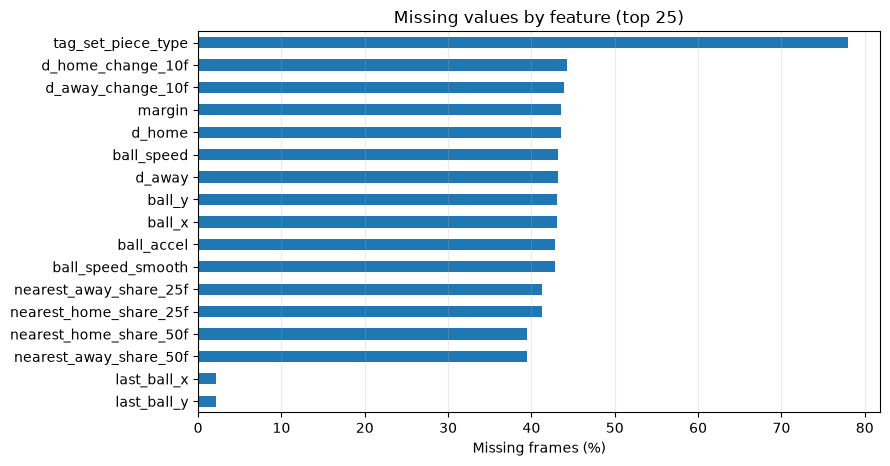

In [22]:
# Missingness by feature (top 25)
missing_pct = 100 * df.isna().mean()
missing_pct = missing_pct[missing_pct > 0].sort_values()

if len(missing_pct):
    ax = missing_pct.tail(25).plot(kind="barh", figsize=(9, max(4, 0.28 * len(missing_pct.tail(25)))))
    ax.set(title="Missing values by feature (top 25)", xlabel="Missing frames (%)", ylabel="")
    ax.grid(axis="x", alpha=.25)
    plt.tight_layout()
    plt.show()
else:
    print("No pandas NaN values found.")

## 3. Frame coverage and tracking availability

Check whether all frames are represented, which frames belong to graded halves, and whether tracking availability changes over time. The expected output has one row per video frame.

In [23]:
if "frame" in df:
    print("Frame sequence continuous:", np.array_equal(df["frame"].to_numpy(), np.arange(len(df))))
    print("First / last frame:", df["frame"].min(), "/", df["frame"].max())

if "half" in df:
    display(df["half"].value_counts(dropna=False).sort_index().rename("frames").to_frame())

if "graded" in df:
    display(df["graded"].value_counts(dropna=False).rename("frames").to_frame())

Frame sequence continuous: True
First / last frame: 0 / 199318


,frames
half,
0,40462
1,79467
2,79390


,frames
graded,
True,158857
False,40462


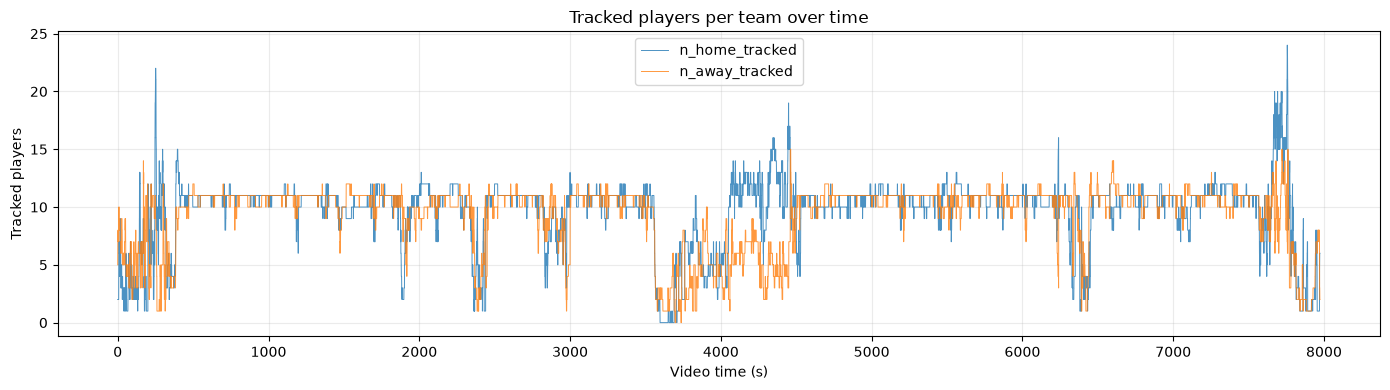

Ball missing: 43.06% of all frames


In [24]:
# Plot tracking availability over time using time in seconds if FPS is known.
FPS = 25  # Update if this game uses a different frame rate.
x_time = df["frame"] / FPS if "frame" in df else np.arange(len(df)) / FPS

availability_cols = [c for c in ["n_home_tracked", "n_away_tracked"] if c in df]
if availability_cols:
    fig, ax = plt.subplots(figsize=(14, 4))
    for col in availability_cols:
        ax.plot(x_time, df[col], label=col, alpha=.8, linewidth=.7)
    ax.set(title="Tracked players per team over time", xlabel="Video time (s)", ylabel="Tracked players")
    ax.legend()
    ax.grid(alpha=.25)
    plt.tight_layout()
    plt.show()

if "ball_missing" in df:
    miss = df["ball_missing"].astype(bool)
    print(f"Ball missing: {miss.mean():.2%} of all frames")

## 4. Ball location on the pitch

A 2D density map shows where the ball is most often observed. It can reveal spatial coverage, long periods in one area, or coordinate problems. Coordinates are in metres according to the feature-extraction script.

This plot includes only observed ball positions; missing positions are excluded.

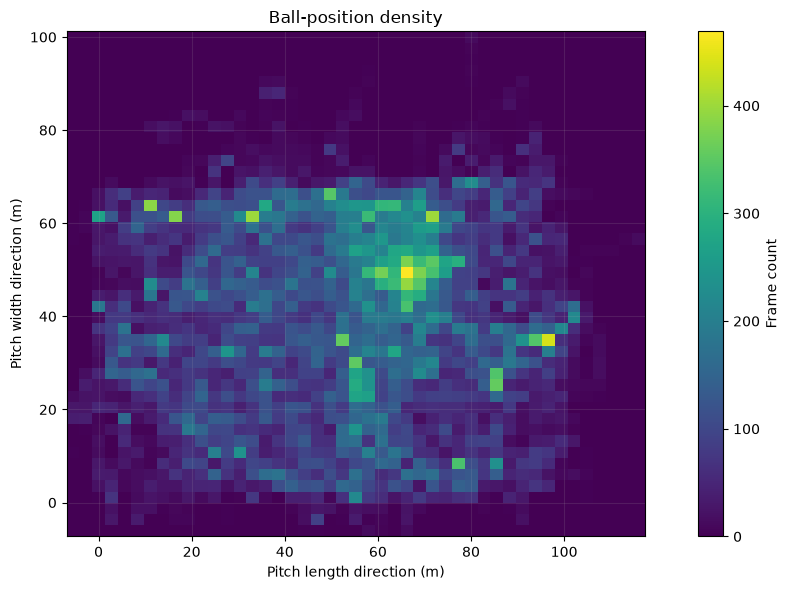

Frames with ball coordinates: 113,488 (56.9%)


In [25]:
if {"ball_x", "ball_y"}.issubset(df.columns):
    valid = df[["ball_x", "ball_y"]].dropna()
    fig, ax = plt.subplots(figsize=(11, 6))
    h = ax.hist2d(valid["ball_x"], valid["ball_y"], bins=45, cmap="viridis")
    plt.colorbar(h[3], ax=ax, label="Frame count")
    ax.set(title="Ball-position density", xlabel="Pitch length direction (m)", ylabel="Pitch width direction (m)")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=.15)
    plt.tight_layout()
    plt.show()
    print(f"Frames with ball coordinates: {len(valid):,} ({len(valid)/len(df):.1%})")
else:
    print("ball_x / ball_y columns not available.")

## 5. Ball movement: speed and acceleration

Inspect the distribution and time series of ball speed. Very high spikes may be genuine kicks or tracking noise; compare them with the video before interpreting them. `ball_speed_smooth` is a rolling median in the extraction script.

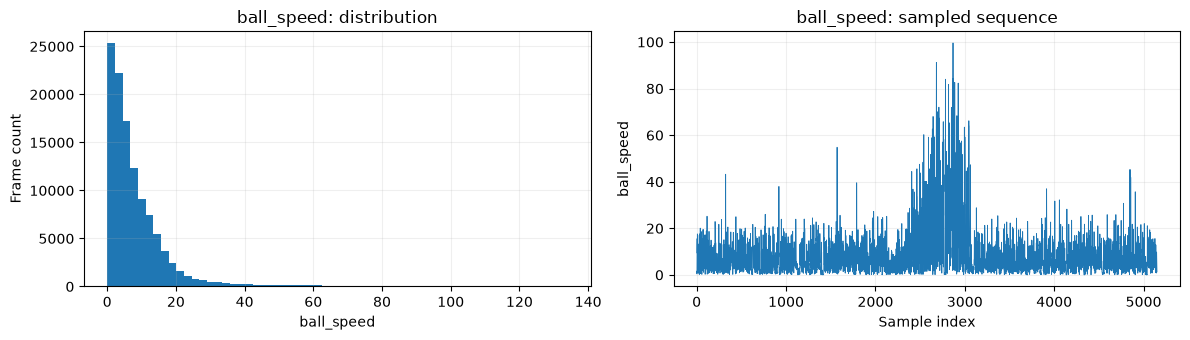

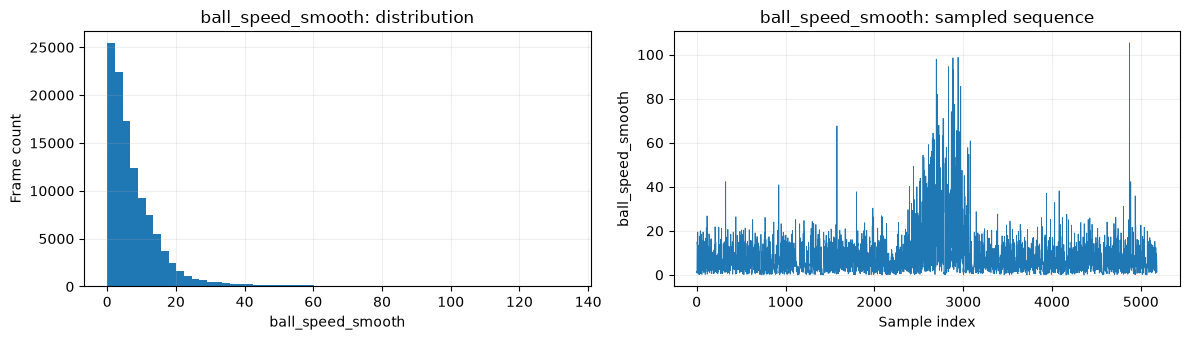

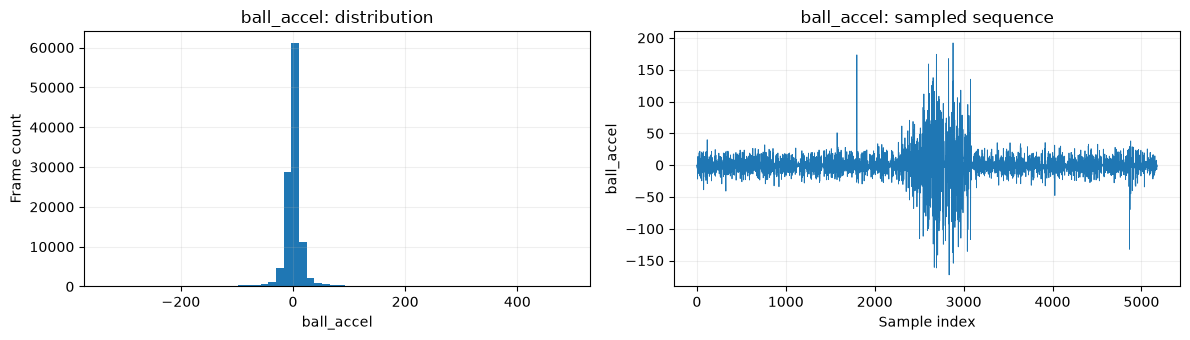

In [26]:
for col in ["ball_speed", "ball_speed_smooth", "ball_accel"]:
    if col in df:
        s = df[col].dropna()
        if len(s):
            fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
            axes[0].hist(s, bins=60)
            axes[0].set(title=f"{col}: distribution", xlabel=col, ylabel="Frame count")
            axes[1].plot(s.iloc[::max(1, len(s)//5000)].to_numpy(), linewidth=.6)
            axes[1].set(title=f"{col}: sampled sequence", xlabel="Sample index", ylabel=col)
            for ax in axes: ax.grid(alpha=.2)
            plt.tight_layout()
            plt.show()

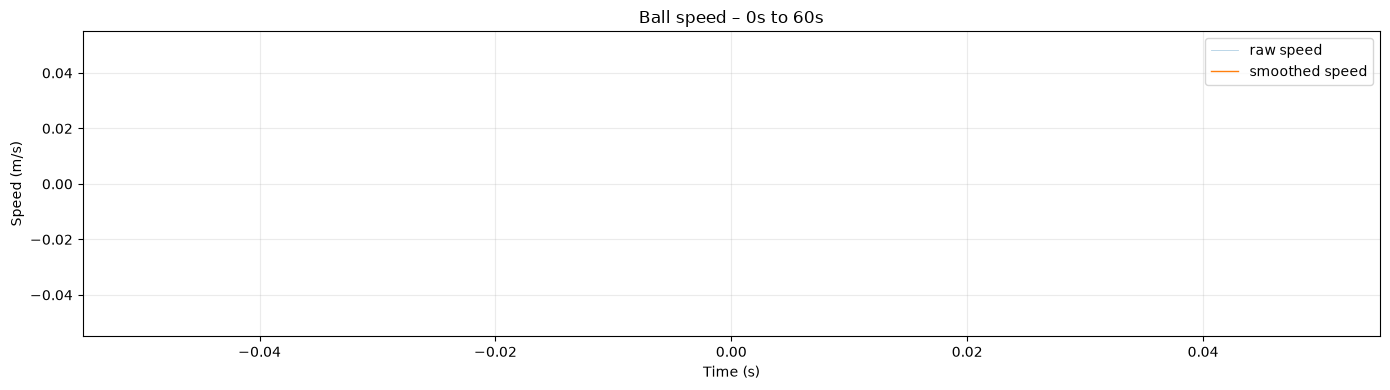

In [27]:
if {"frame", "ball_speed", "ball_speed_smooth"}.issubset(df.columns):
    # Plot a manageable segment; change START_S / DURATION_S to inspect a moment.
    START_S, DURATION_S = 0, 60
    start, end = int(START_S * FPS), int((START_S + DURATION_S) * FPS)
    seg = df.iloc[start:end]
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(seg["frame"]/FPS, seg["ball_speed"], alpha=.35, linewidth=.6, label="raw speed")
    ax.plot(seg["frame"]/FPS, seg["ball_speed_smooth"], linewidth=1, label="smoothed speed")
    ax.set(title=f"Ball speed – {START_S}s to {START_S + DURATION_S}s", xlabel="Time (s)", ylabel="Speed (m/s)")
    ax.legend(); ax.grid(alpha=.25)
    plt.tight_layout(); plt.show()

## 6. Player proximity and the nearest-team signal

`d_home` and `d_away` are the distances from the ball to the nearest tracked player on each team. `margin = d_away - d_home`: positive values mean the nearest HOME player is closer; negative values mean the nearest AWAY player is closer.

This is a proximity signal, **not proof of possession**.

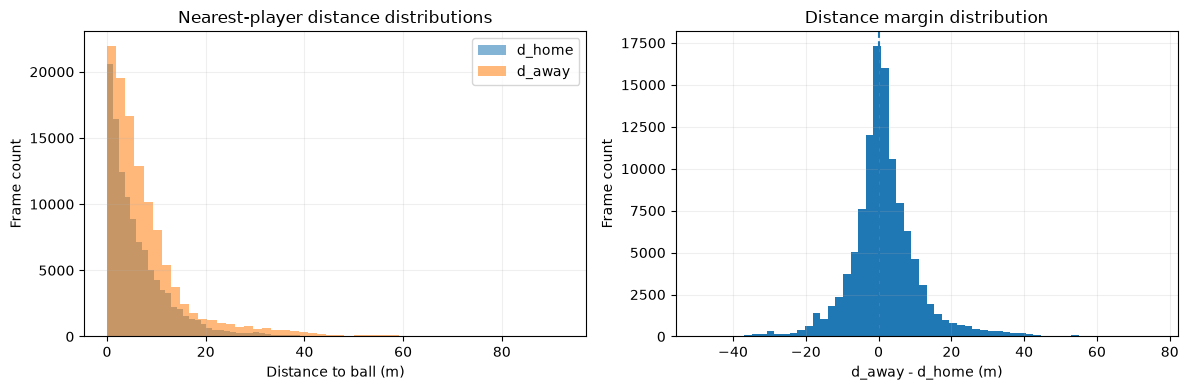

In [28]:
if {"d_home", "d_away"}.issubset(df.columns):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for col in ["d_home", "d_away"]:
        if col in df:
            axes[0].hist(df[col].dropna(), bins=50, alpha=.55, label=col)
    axes[0].set(title="Nearest-player distance distributions", xlabel="Distance to ball (m)", ylabel="Frame count")
    axes[0].legend(); axes[0].grid(alpha=.2)

    if "margin" in df:
        axes[1].hist(df["margin"].dropna(), bins=60)
        axes[1].axvline(0, linestyle="--")
        axes[1].set(title="Distance margin distribution", xlabel="d_away - d_home (m)", ylabel="Frame count")
        axes[1].grid(alpha=.2)
    plt.tight_layout(); plt.show()

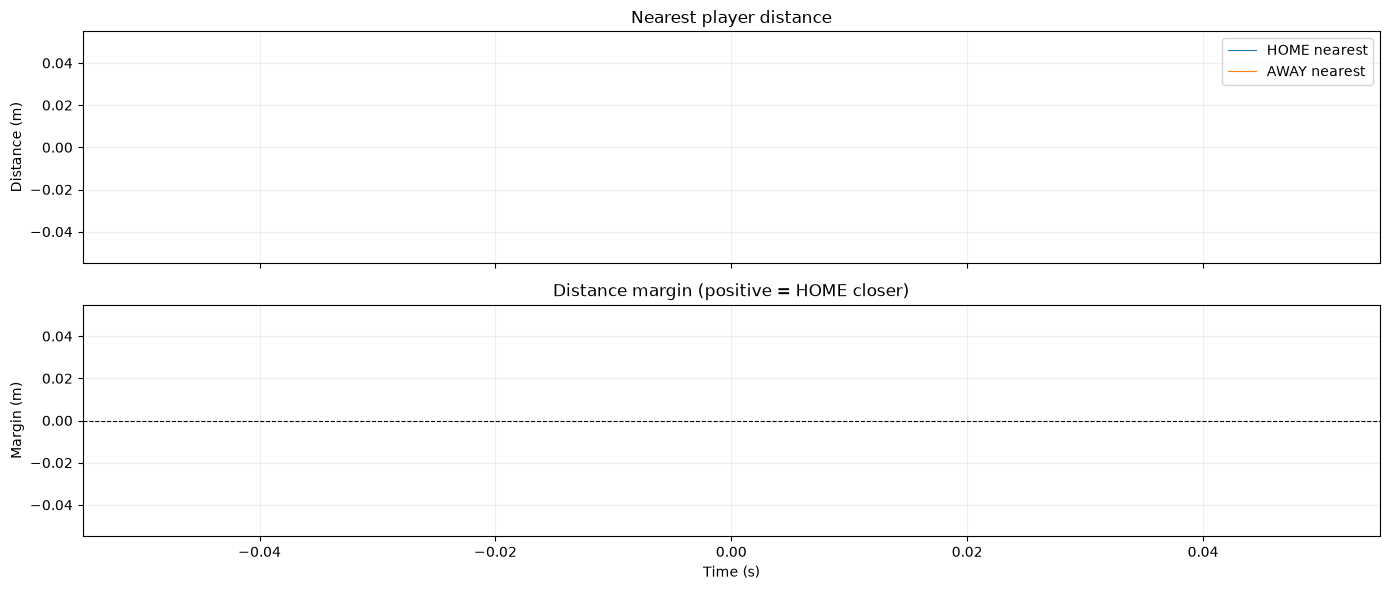

In [29]:
# Time series of nearest distances and margin for a selected window.
if {"frame", "d_home", "d_away"}.issubset(df.columns):
    START_S, DURATION_S = 0, 60
    seg = df.iloc[int(START_S*FPS):int((START_S+DURATION_S)*FPS)]
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    axes[0].plot(seg["frame"]/FPS, seg["d_home"], label="HOME nearest", linewidth=.8)
    axes[0].plot(seg["frame"]/FPS, seg["d_away"], label="AWAY nearest", linewidth=.8)
    axes[0].set(ylabel="Distance (m)", title="Nearest player distance")
    axes[0].legend(); axes[0].grid(alpha=.2)
    if "margin" in seg:
        axes[1].plot(seg["frame"]/FPS, seg["margin"], linewidth=.8)
        axes[1].axhline(0, color="black", linestyle="--", linewidth=.8)
        axes[1].set(ylabel="Margin (m)", xlabel="Time (s)", title="Distance margin (positive = HOME closer)")
        axes[1].grid(alpha=.2)
    plt.tight_layout(); plt.show()

## 7. Number of players near the ball

The extraction code uses a 5 m `near` radius and a 2 m `very-near` radius. Compare teams and inspect how often there are no players nearby, one nearby player, or several players crowding the ball.

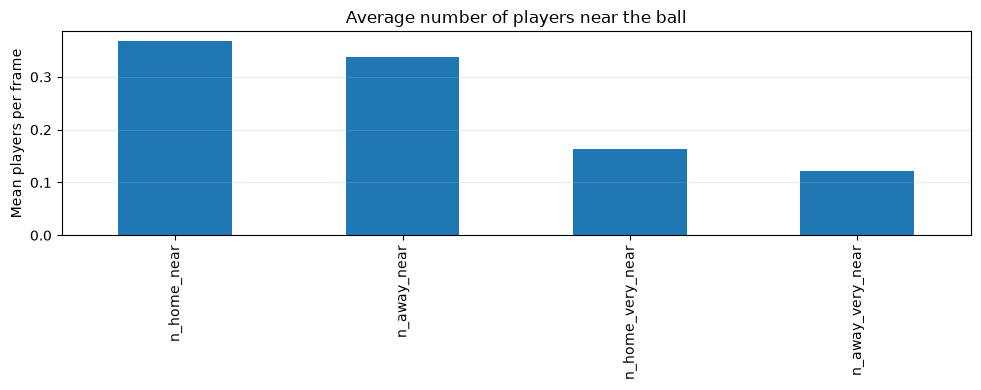

,count,mean,std,min,25%,50%,75%,max
n_home_near,199319.0,0.367898,0.604702,0.0,0.0,0.0,1.0,6.0
n_away_near,199319.0,0.337268,0.627119,0.0,0.0,0.0,1.0,8.0
n_home_very_near,199319.0,0.164325,0.375573,0.0,0.0,0.0,0.0,3.0
n_away_very_near,199319.0,0.122422,0.339842,0.0,0.0,0.0,0.0,4.0


In [30]:
count_cols = [c for c in ["n_home_near", "n_away_near", "n_home_very_near", "n_away_very_near"] if c in df]
if count_cols:
    fig, ax = plt.subplots(figsize=(10, 4))
    df[count_cols].mean().plot(kind="bar", ax=ax)
    ax.set(title="Average number of players near the ball", ylabel="Mean players per frame", xlabel="")
    ax.grid(axis="y", alpha=.25)
    plt.tight_layout(); plt.show()

    display(df[count_cols].describe().T)

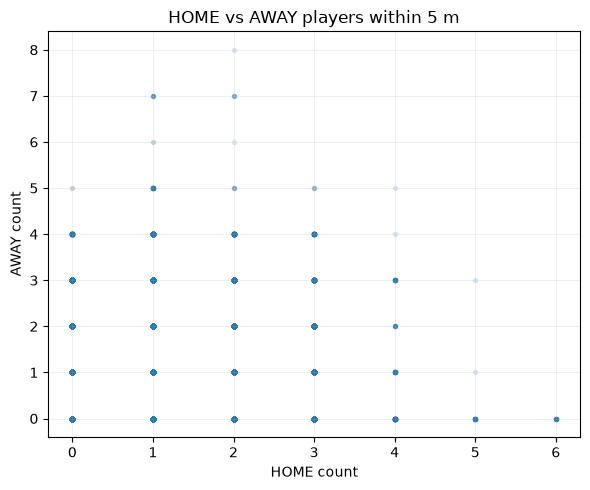

In [31]:
if {"n_home_near", "n_away_near"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(df["n_home_near"], df["n_away_near"], alpha=.12, s=8)
    ax.set(title="HOME vs AWAY players within 5 m", xlabel="HOME count", ylabel="AWAY count")
    ax.grid(alpha=.2)
    plt.tight_layout(); plt.show()

## 8. Nearest team, persistence and run lengths

`nearest_team` encodes the team whose player is closest to the ball (the numeric codes come from the baseline implementation). The share features are trailing proportions over 25 and 50 frames; `nearest_team_run_frames` counts consecutive frames with the same nearest team.

Use the value counts and run-length distributions to see whether the raw nearest-team signal flickers frequently.

,frames
nearest_team,
-1,85831
0,63964
1,49524


Check the HOME / AWAY / NOBODY numeric mapping in starter.baseline before interpreting codes.


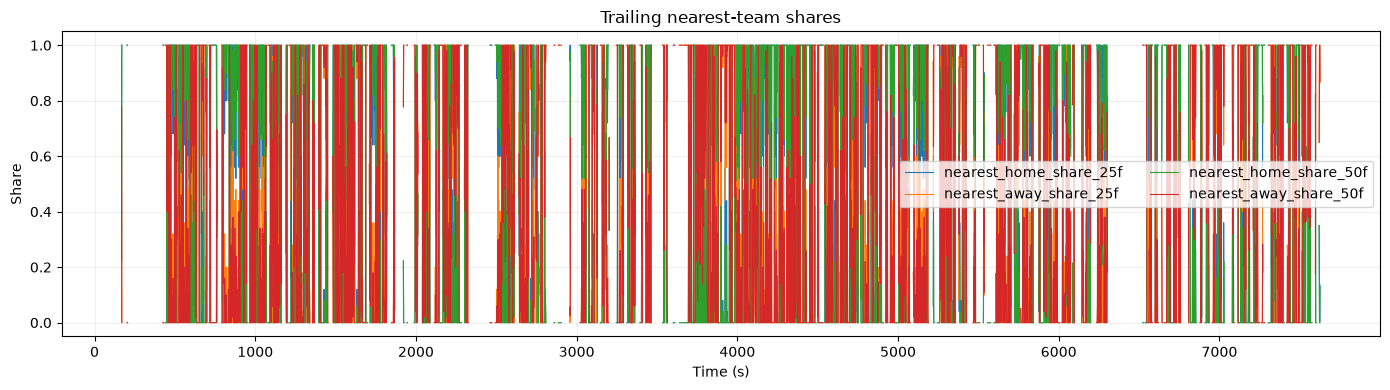

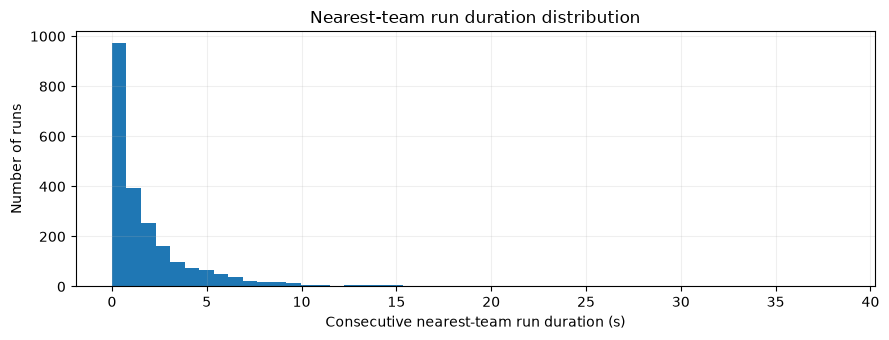

In [32]:
if "nearest_team" in df:
    display(df["nearest_team"].value_counts(dropna=False).sort_index().rename("frames").to_frame())
    print("Check the HOME / AWAY / NOBODY numeric mapping in starter.baseline before interpreting codes.")

share_cols = [c for c in df.columns if c.startswith("nearest_home_share_") or c.startswith("nearest_away_share_")]
if share_cols:
    fig, ax = plt.subplots(figsize=(14, 4))
    sample_step = max(1, len(df)//8000)
    for col in share_cols:
        ax.plot(x_time[::sample_step], df[col].iloc[::sample_step], label=col, linewidth=.8)
    ax.set(title="Trailing nearest-team shares", xlabel="Time (s)", ylabel="Share")
    ax.legend(ncol=2); ax.grid(alpha=.2)
    plt.tight_layout(); plt.show()

if "nearest_team_run_frames" in df:
    runs = df.loc[df["nearest_team_run_frames"].diff().fillna(1) <= 0, "nearest_team_run_frames"]
    # More reliable run extraction: each new run starts when run length returns to 1.
    starts = df["nearest_team_run_frames"].eq(1)
    run_lengths = df.loc[starts, "nearest_team_run_frames"]
    # The run start row is 1, so derive completed run lengths from resets.
    vals = df["nearest_team_run_frames"].to_numpy()
    ends = np.r_[np.flatnonzero(np.diff(vals) < 0), len(vals)-1]
    completed = vals[ends] if len(vals) else np.array([])
    if len(completed):
        plt.figure(figsize=(9, 3.5))
        plt.hist(completed / FPS, bins=50)
        plt.xlabel("Consecutive nearest-team run duration (s)")
        plt.ylabel("Number of runs")
        plt.title("Nearest-team run duration distribution")
        plt.grid(alpha=.2); plt.tight_layout(); plt.show()

## 9. Smart Tagging coverage and overlaps

Inspect the frequency and duration of tags. These annotations may be sparse, and their frame ranges can overlap. The plots show tag presence, not whether the annotations are correct.

/var/folders/qt/d9mrqr1s6z536_h0j4_x7wpc0000gp/T/ipykernel_8264/2315921870.py:4: Pandas4Warning: 'bool' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  "active_frames": [df[c].fillna(False).astype(bool).sum() for c in tag_cols],
/var/folders/qt/d9mrqr1s6z536_h0j4_x7wpc0000gp/T/ipykernel_8264/2315921870.py:5: Pandas4Warning: 'bool' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  "active_pct": [100*df[c].fillna(False).astype(bool).mean() for c in tag_cols],


,active_frames,active_pct
tag_team_def,180917,90.767564
tag_team_poss,129481,64.961695
tag_dead,43987,22.068644
tag_set_piece_type,43987,22.068644
tag_goal,16503,8.279692


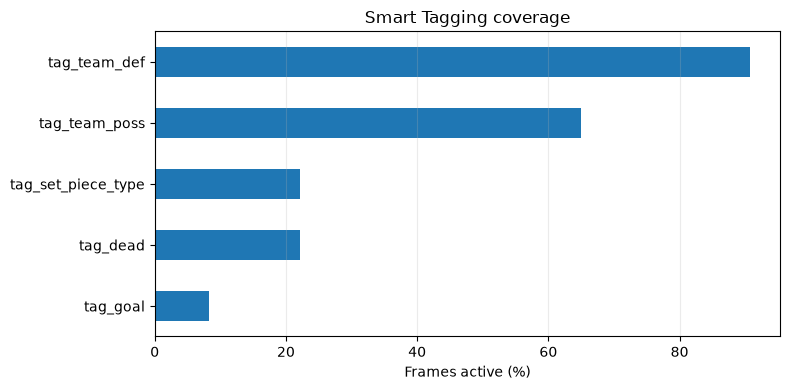

,frames
tag_set_piece_type,
THROW-IN,20980
CORNER KICK,9220
GOAL KICK,8662
FREE KICK,4375
KICK OFF (AFTER GOAL),500
KICK OFF (START),250


In [33]:
tag_cols = [c for c in df.columns if c.startswith("tag_") and df[c].dtype != "object"]
if tag_cols:
    tag_summary = pd.DataFrame({
        "active_frames": [df[c].fillna(False).astype(bool).sum() for c in tag_cols],
        "active_pct": [100*df[c].fillna(False).astype(bool).mean() for c in tag_cols],
    }, index=tag_cols)
    display(tag_summary.sort_values("active_pct", ascending=False))
    ax = tag_summary["active_pct"].sort_values().plot(kind="barh", figsize=(8, 4))
    ax.set(title="Smart Tagging coverage", xlabel="Frames active (%)", ylabel="")
    ax.grid(axis="x", alpha=.25); plt.tight_layout(); plt.show()

if "tag_set_piece_type" in df:
    display(df.loc[df["tag_set_piece_type"].fillna("").ne(""), "tag_set_piece_type"].value_counts().to_frame("frames"))

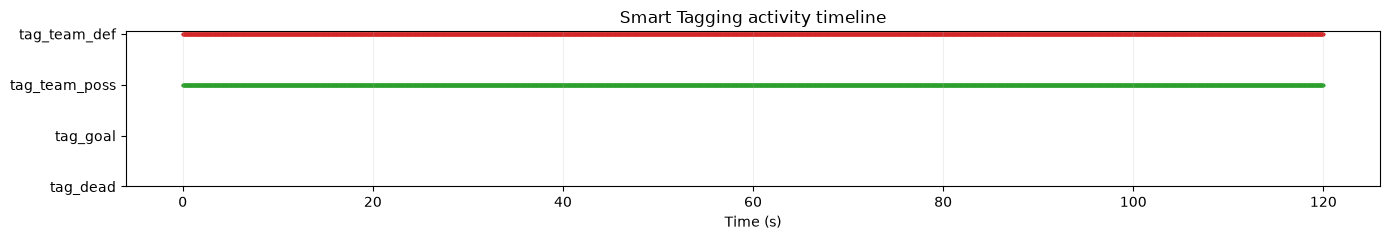

In [34]:
# Plot tag intervals in a selected time window as a compact raster.
raster_cols = [c for c in ["tag_dead", "tag_goal"] if c in df]
for c in ["tag_team_poss", "tag_team_def"]:
    if c in df: raster_cols.append(c)

if raster_cols:
    START_S, DURATION_S = 0, 120
    seg = df.iloc[int(START_S*FPS):int((START_S+DURATION_S)*FPS)]
    fig, ax = plt.subplots(figsize=(14, max(2.5, .45*len(raster_cols))))
    for row, col in enumerate(raster_cols):
        values = seg[col]
        if col in ["tag_dead", "tag_goal"]:
            active = values.fillna(False).astype(bool).to_numpy()
        else:
            # Numeric team codes: plot non-zero values; consult baseline mapping.
            active = values.fillna(0).to_numpy() != 0
        ax.scatter(seg.loc[active, "frame"]/FPS, np.full(active.sum(), row), s=3, label=col)
    ax.set_yticks(range(len(raster_cols)), raster_cols)
    ax.set(xlabel="Time (s)", title="Smart Tagging activity timeline")
    ax.grid(axis="x", alpha=.2); plt.tight_layout(); plt.show()

## 10. Compare halves / graded and ungraded sections

Use this to spot differences in tracking coverage or feature distributions between halves. Do not interpret ungraded sections as labelled possession data.

In [35]:
if "half" in df:
    numeric_candidates = [c for c in [
        "ball_speed_smooth", "d_home", "d_away", "margin",
        "n_home_near", "n_away_near", "n_home_tracked", "n_away_tracked"
    ] if c in df]
    if numeric_candidates:
        display(df.groupby("half")[numeric_candidates].agg(["mean", "median", "std"]).round(2))

ball_speed_smooth               d_home              d_away                \
                  mean median    std   mean median   std   mean median    std   
half                                                                            
0                15.99  10.09  16.71  11.34  10.48  7.27  17.68  13.93  13.90   
1                 6.53   4.99   5.60   5.23   3.42  5.59   6.24   4.78   6.47   
2                 6.84   5.17   6.36   5.42   3.69  6.02   6.01   4.56   5.51   

     margin  ... n_home_near n_away_near              n_home_tracked         \
       mean  ...         std        mean median   std           mean median   
half         ...                                                              
0      5.91  ...        0.32        0.10    0.0  0.32           7.53    7.0   
1      0.90  ...        0.64        0.38    0.0  0.65          10.05   11.0   
2      0.59  ...        0.64        0.41    0.0  0.69          10.35   11.0   

           n_away_tracked               
       std           mean median   std  
half                                    
0     4.82           5.51    5.0  2.99  
1     2.20          10.07   11.0  1.96  
2     1.68          10.50   11.0  1.44  

[3 rows x 24 columns]

## 11. Feature relationships

A correlation heatmap can show redundant signals or unexpected relationships. Correlation is descriptive, not causal, and binary/team-coded columns should be interpreted carefully.

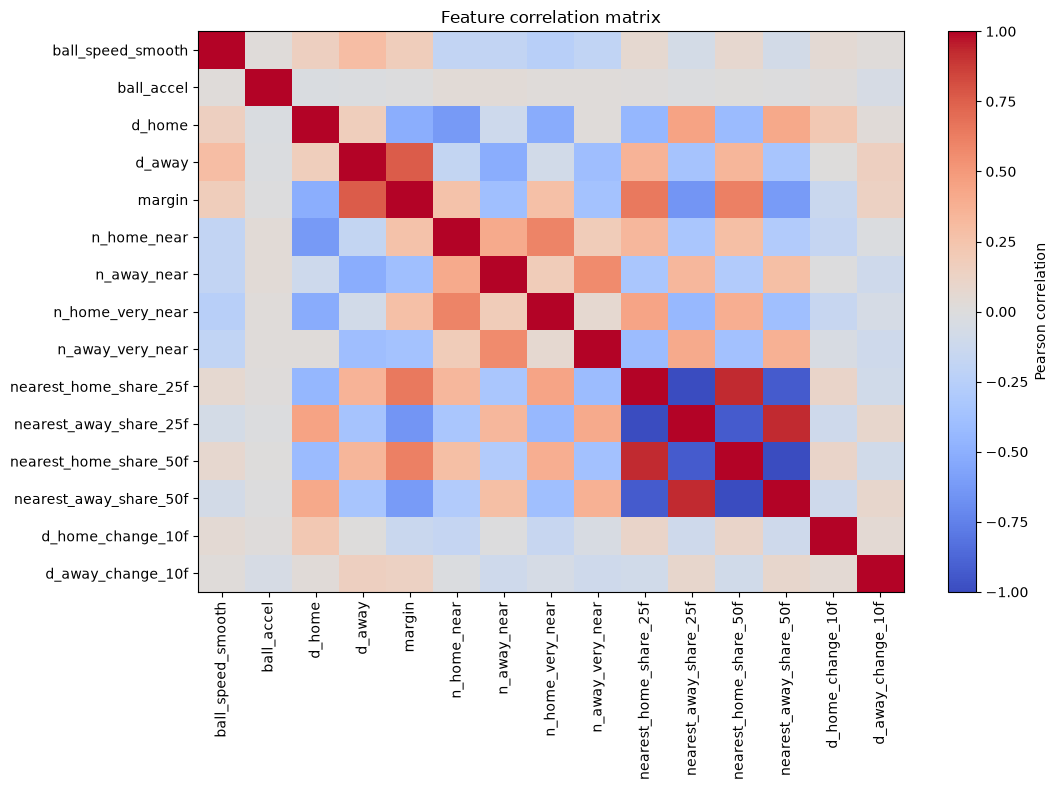

In [36]:
corr_cols = [c for c in [
    "ball_speed_smooth", "ball_accel", "d_home", "d_away", "margin",
    "n_home_near", "n_away_near", "n_home_very_near", "n_away_very_near",
    "nearest_home_share_25f", "nearest_away_share_25f",
    "nearest_home_share_50f", "nearest_away_share_50f",
    "d_home_change_10f", "d_away_change_10f"
] if c in df.columns]
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr()
    fig, ax = plt.subplots(figsize=(11, 8))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
    ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90)
    ax.set_yticks(range(len(corr_cols)), corr_cols)
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    ax.set_title("Feature correlation matrix")
    plt.tight_layout(); plt.show()

## 12. Build a compact diagnostic table

This table highlights candidate data-quality issues for manual inspection. Thresholds are prompts for investigation, not universal definitions of bad data.

In [37]:
diagnostics = {}
if "ball_missing" in df:
    diagnostics["ball_missing_pct"] = 100 * df["ball_missing"].fillna(False).mean()
if "ball_out" in df:
    diagnostics["ball_out_pct"] = 100 * df["ball_out"].fillna(False).mean()
for c in ["n_home_tracked", "n_away_tracked"]:
    if c in df:
        diagnostics[f"{c}_zero_pct"] = 100 * (df[c].fillna(0) == 0).mean()
for c in ["d_home", "d_away", "ball_speed_smooth"]:
    if c in df:
        diagnostics[f"{c}_missing_pct"] = 100 * df[c].isna().mean()

display(pd.Series(diagnostics, name="value").to_frame())

,value
ball_missing_pct,43.062127
ball_out_pct,2.161359
n_home_tracked_zero_pct,1.060110
n_away_tracked_zero_pct,0.105860
d_home_missing_pct,43.513162
d_away_missing_pct,43.147417
ball_speed_smooth_missing_pct,42.800737
